**Célula 1 – setup e dados:**

In [1]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

%load_ext autoreload
%autoreload 2

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from src.utils import set_seed, SEED
from src.color_data import get_color_splits, to_grayscale, color_histogram
from src.representation import compute_hog, train_autoencoder, save_autoencoder, ae_encode
from src.retrieval import SearchSpace, retrieve, precision_at_k

set_seed()
X_gal, t_gal, c_gal, X_q, t_q, c_q = get_color_splits()
print("Galeria:", X_gal.shape, "| Queries:", X_q.shape)

Galeria: (2163, 2352) | Queries: (541, 2352)


**Célula 2 – treinar o autoencoder a cores (só com a galeria):**

Treino: 33.2 s | melhor val MSE = 0.00511 (época 165)


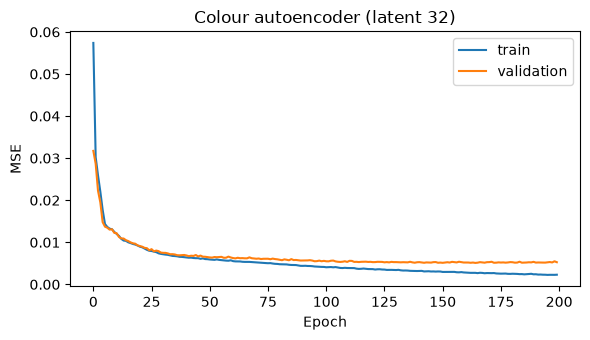

In [2]:
X_ae_tr, X_ae_va = train_test_split(X_gal, test_size=0.1, random_state=SEED)

start = time.perf_counter()
ae_color, hist = train_autoencoder(X_ae_tr, X_ae_va, latent_dim=32, epochs=200, batch_size=64)
print(f"Treino: {time.perf_counter() - start:.1f} s | melhor val MSE = {min(hist['val_loss']):.5f} "
      f"(época {int(np.argmin(hist['val_loss'])) + 1})")
save_autoencoder(ae_color, "models/ae_color_32.pt")

plt.figure(figsize=(6, 3.5))
plt.plot(hist["train_loss"], label="train")
plt.plot(hist["val_loss"], label="validation")
plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.title("Colour autoencoder (latent 32)")
plt.legend(); plt.tight_layout()
plt.savefig("results/figures/14b_color_ae_curve.png", dpi=150, bbox_inches="tight")
plt.show()

**Célula 3 – os três espaços e as duas precisões:**

In [ ]:
spaces = [
    SearchSpace("colour (RGB histogram)", color_histogram, X_gal),
    SearchSpace("texture/edges (HOG, gray)", lambda X: compute_hog(to_grayscale(X)), X_gal),
    SearchSpace("learned (colour AE-32)", lambda X: ae_encode(ae_color, X), X_gal),
]


def chance_level(gallery_labels):
    _, counts = np.unique(gallery_labels, return_counts=True)
    p = counts / counts.sum()
    return float(np.sum(p ** 2))


rows = [{"space": "random (chance)", "colour p@5": chance_level(c_gal), "colour p@10": chance_level(c_gal),
         "type p@5": chance_level(t_gal), "type p@10": chance_level(t_gal)}]
for s in spaces:
    idx, _ = s.search(X_q, k=10)                                   
    rows.append({"space": s.name,
                 "colour p@5": precision_at_k(idx, c_gal, c_q, 5),
                 "colour p@10": precision_at_k(idx, c_gal, c_q, 10),
                 "type p@5": precision_at_k(idx, t_gal, t_q, 5),
                 "type p@10": precision_at_k(idx, t_gal, t_q, 10)})
color_table = pd.DataFrame(rows)
print(color_table.round(3).to_string(index=False))
color_table.to_csv("results/tables/14b_color_retrieval.csv", index=False)

                    space  colour p@5  colour p@10  type p@5  type p@10
          random (chance)       0.172        0.172     0.201      0.201
   colour (RGB histogram)       0.708        0.680     0.458      0.435
texture/edges (HOG, gray)       0.261        0.255     0.767      0.751
   learned (colour AE-32)       0.541        0.506     0.762      0.750


**Célula 4 – painéis (uma query aleatória por tipo):**

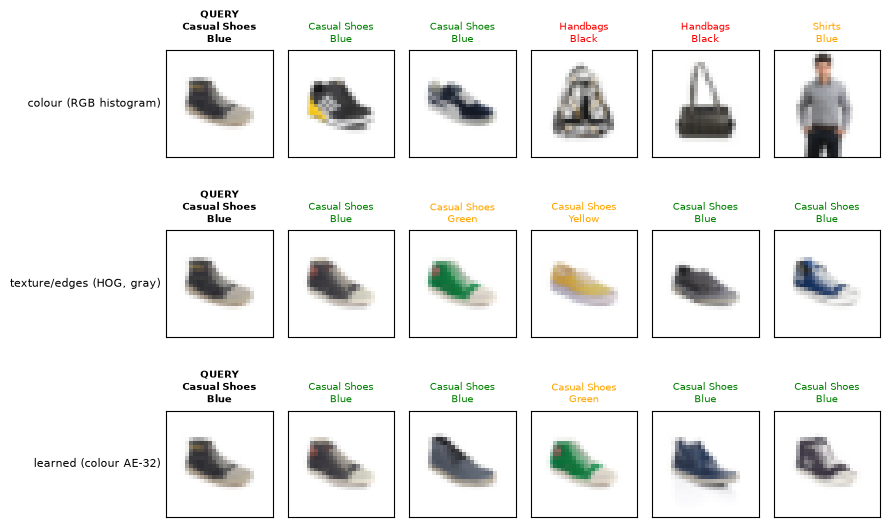

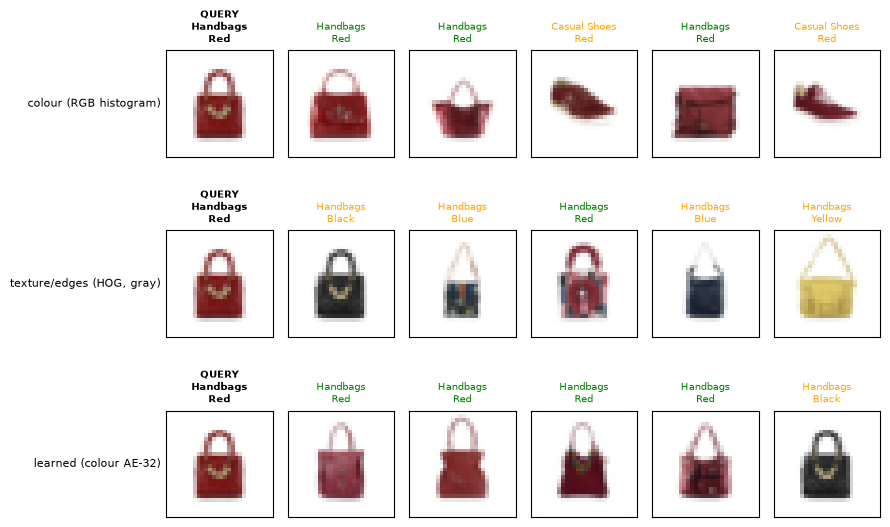

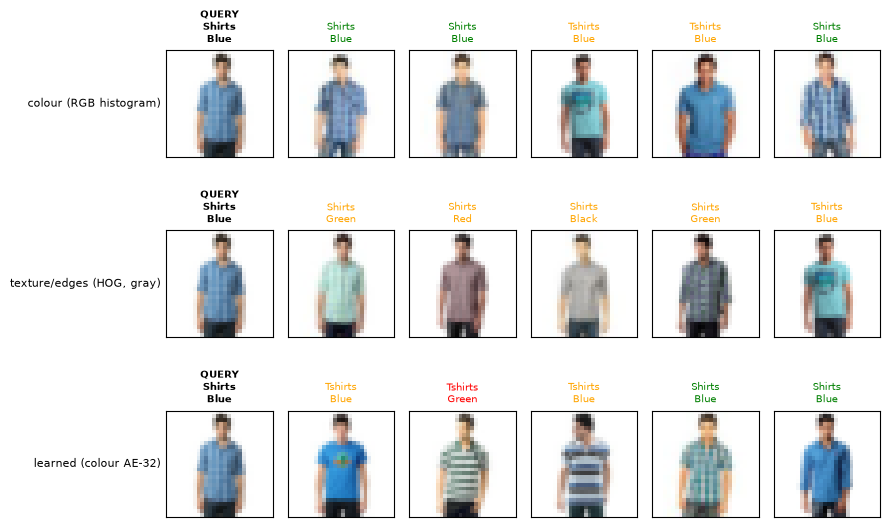

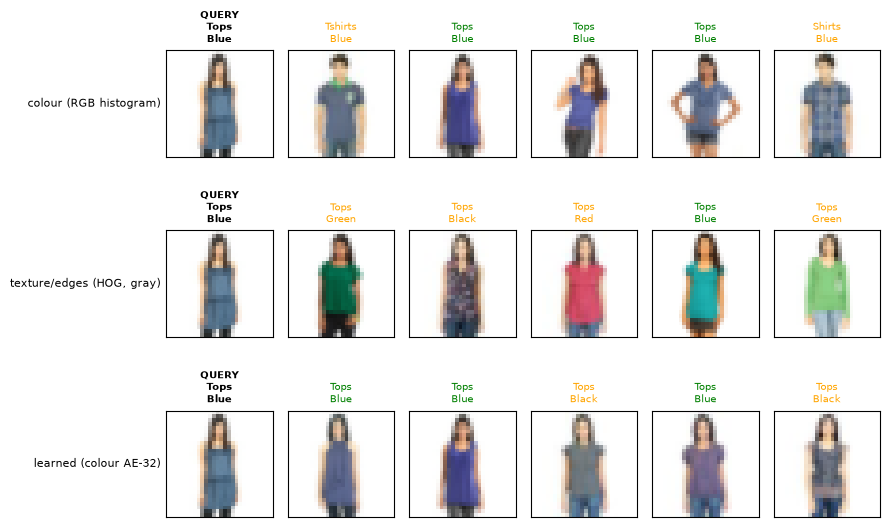

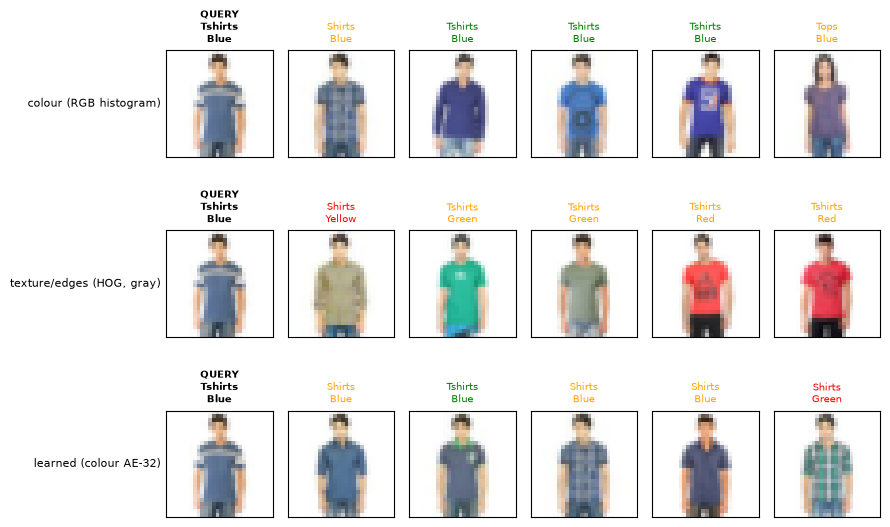

In [4]:
def plot_color_panel(q, results, k=5, save_path=None):
    """Legendas: verde = mesmo tipo E mesma cor; laranja = só um dos dois; vermelho = nenhum."""
    fig, axes = plt.subplots(len(results), k + 1, figsize=((k + 1) * 1.5, len(results) * 1.9))
    for r, (name, (idx, _)) in enumerate(results.items()):
        axes[r, 0].imshow(X_q[q].reshape(28, 28, 3))
        axes[r, 0].set_title(f"QUERY\n{t_q[q]}\n{c_q[q]}", fontsize=7, fontweight="bold")
        axes[r, 0].set_ylabel(name, fontsize=8, rotation=0, ha="right", va="center")
        for j, i in enumerate(idx[0, :k]):
            same_t, same_c = t_gal[i] == t_q[q], c_gal[i] == c_q[q]
            color = "green" if (same_t and same_c) else ("orange" if (same_t or same_c) else "red")
            axes[r, j + 1].imshow(X_gal[i].reshape(28, 28, 3))
            axes[r, j + 1].set_title(f"{t_gal[i]}\n{c_gal[i]}", fontsize=7, color=color)
    for ax in axes.ravel():
        ax.set_xticks([]); ax.set_yticks([])
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


rng = np.random.default_rng(SEED)
for t in np.unique(t_q):
    q = rng.choice(np.where(t_q == t)[0])                         
    results = retrieve(X_q[q], spaces, k=5)
    plot_color_panel(q, results, save_path=f"results/figures/retrieval_panels/color_{t.replace(' ', '_')}.png")